# Code switching: from the Steane code to the [[15,1,3]] code

> **In short.**
> * **The setting.** No code has a transversal gate for every operation (Eastin–Knill). The Steane code [[7,1,3]] has transversal $H$, $S$ and CNOT, but not $T$; the [[15,1,3]] Reed–Muller code has transversal $T$, but not $H$. Moving the logical qubit from one code to the other, *code switching*, gives a universal set of gates.
> * **The protocol** (L. Yeh's thesis, Section 6.6, after Quan et al. 2018 and Anderson et al. 2014). Put 8 more qubits in a fixed state, the *cube state*, next to the Steane block. Measure three operators on all 15 qubits (the *gauge operators*); each outcome is random. Apply an $X$ correction chosen by the outcomes. The 15 qubits are then in the [[15,1,3]] code, with the logical state unchanged.
> * **What the tool finds, from the gates alone.** Question 1: the Steane code plus the cube state before, the [[15,1,3]] code after. Questions 2 and 3: the switch leaves the logical state unchanged in every run. And with `circuit_distance`: the switch as written has circuit distance 2, so one fault in preparing the cube state and one in the measurements can corrupt the logical qubit unnoticed; checking the cube state before using it brings the distance to 3, the distance of the codes.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders. In the pictures of codes, each coloured patch is one check, a red dot one qubit.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

The 15 qubits are numbered so that qubit $c - 1$ sits at the 4-bit binary number $c$ ($c = 1, \dots, 15$). Qubits 0–6 (the numbers with the top bit 0) hold the Steane code; qubits 7–14 (top bit 1) are the cube.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Measurement
from pyzx.css import generate_css_encoder_graph
from pyzx.linalg import Mat2
from zxqec.qprogram import QProgram, ParityControlled, circuit_distance
from zxqec.codes import code_of, check_diagram
from zxqec.spacetime import draw_program, draw_relaxed, draw_relaxed_3d

# the Steane code on qubits 0-6, from the input on qubit 2 (its checks: X and Z on each face of a triangle)
STEANE = [CNOT(2, 4), CNOT(2, 5), HAD(0), CNOT(0, 2), CNOT(0, 4), CNOT(0, 6), HAD(1), CNOT(1, 2), CNOT(1, 5),
          CNOT(1, 6), HAD(3), CNOT(3, 4), CNOT(3, 5), CNOT(3, 6)]
TRIANGLE = [[0, 2, 4, 6], [1, 2, 5, 6], [3, 4, 5, 6]]
# the cube state on qubits 7-14: X and Z on every face of a cube (the eight qubits are its corners)
CUBE = [HAD(7), CNOT(7, 10), CNOT(7, 12), CNOT(7, 13), HAD(8), CNOT(8, 10), CNOT(8, 12), CNOT(8, 14),
        HAD(9), CNOT(9, 10), CNOT(9, 13), CNOT(9, 14), HAD(11), CNOT(11, 12), CNOT(11, 13), CNOT(11, 14)]
CUBE_FACES = [[8, 10, 12, 14], [7, 9, 11, 13], [9, 10, 13, 14], [7, 8, 11, 12], [11, 12, 13, 14], [7, 8, 9, 10]]
# the three gauge operators: Z on these four qubits each, measured by helpers 15, 16, 17 (outcomes c[0..2])
GAUGE = [[2, 6, 10, 14], [4, 6, 12, 14], [5, 6, 13, 14]]
# the correction for outcome c[k] = 1: X on face k of the Steane triangle
FIX = [[3, 4, 5, 6], [1, 2, 5, 6], [0, 2, 4, 6]]

## 1. The program

Four stages: encode the Steane code, prepare the cube state, measure the three gauge operators, fix the gauge. The program is built twice: as written, and with the cube state *checked* before it is used (Part 4): four of its faces, $X$ on four qubits each, are measured with helpers 18–21, whose outcomes $c[3]$–$c[6]$ must be 0 for a correct cube state.

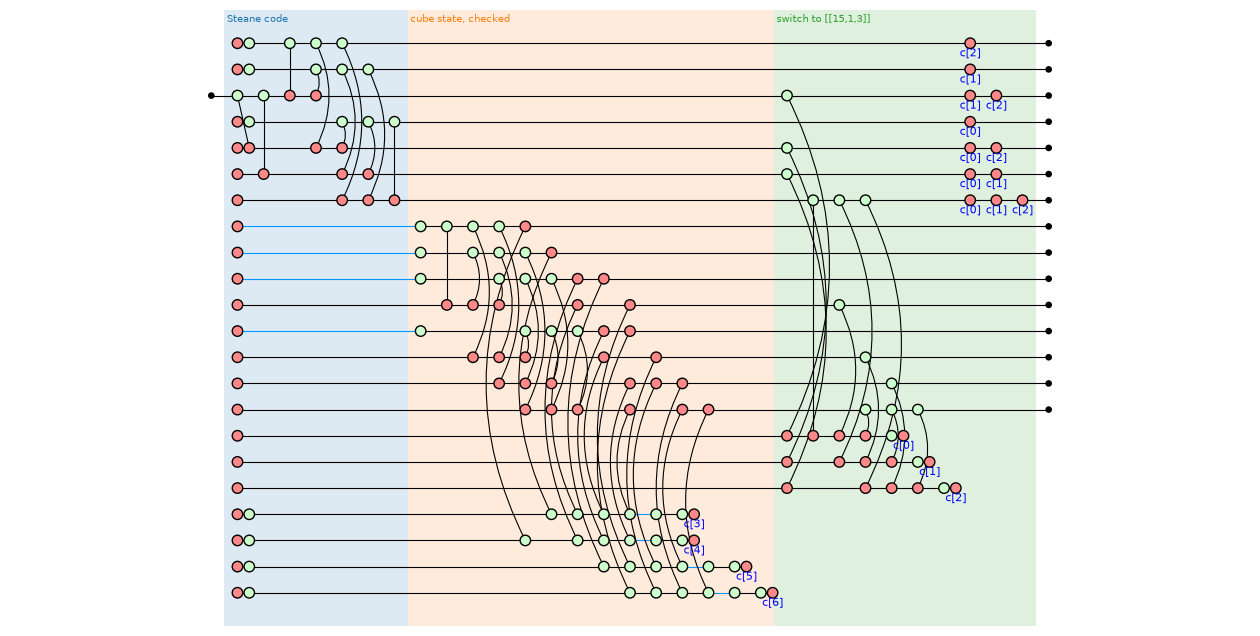

In [2]:
programs = {}
for checked in (False, True):
    p = QProgram(22, bits=7, initial_states={**{q: '0' for q in range(22) if q != 2}, 18: '+', 19: '+', 20: '+', 21: '+'})
    c = Circuit(22, bit_amount=7)
    for gate in STEANE:
        c.add_gate(gate)
    p.add_circuit(c, name='Steane code')
    c = Circuit(22, bit_amount=7)
    for gate in CUBE:
        c.add_gate(gate)
    if checked:
        for k, face in enumerate(CUBE_FACES[:2] + CUBE_FACES[2:6:2]):      # four independent faces
            for q in face:
                c.add_gate(CNOT(18 + k, q))
            c.add_gate(HAD(18 + k))
            c.add_gate(Measurement(18 + k, 3 + k))
    p.add_circuit(c, name='cube state' + (', checked' if checked else ''))
    c = Circuit(22, bit_amount=7)
    for k, op in enumerate(GAUGE):
        for q in op:
            c.add_gate(CNOT(q, 15 + k))
        c.add_gate(Measurement(15 + k, k))
    p.add_circuit(c, name='measure the gauge operators')
    c = Circuit(22, bit_amount=7)
    for k, face in enumerate(FIX):
        for q in face:
            c.add_gate(ParityControlled('X', q, ['c[%d]' % k]))
    p.add_circuit(c, name='gauge fixing')
    programs[checked] = p
plain, p = programs[False], programs[True]
level = p.group_stages([(0, 0, 'Steane code', 'encoder'), (1, 1, 'cube state, checked', 'state preparation'),
                        (2, 3, 'switch to [[15,1,3]]', 'code switching')])
draw_program(p, level=level, show_time=False, labels=False, figsize=(16, 8))

## 2. Question 1: which code, before and after

The tool reads the code off the program cut after each stage. Before the switch: the Steane code on qubits 0–6 and, on qubits 7–14, a state with no logical qubit (`[[8,0]]`), the cube state. After the switch: a [[15,1,3]] code, every sign $+$. The last line compares its checks (up to signs) with those of the Reed–Muller code built by PyZX from its four $X$-checks (`pyzx.css`).

In [3]:
print(p.code_at(1).restricted(list(range(15))))
print()
after = p.code_at(3)
print(after)
rows = [[(c >> b) & 1 for c in range(1, 16)] for b in range(4)]       # qubit c - 1 is in check b if bit b of c is 1
rm, _ = generate_css_encoder_graph(Mat2(rows), Mat2([[1] * 15]), 'Z-X')
rm.auto_detect_io()
print("\nthe [[15,1,3]] Reed-Muller code:", after.same_code_as(code_of(rm)))

[[7, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6
    stabilizer +XXIXIIX
    stabilizer +XXIIXXI
    stabilizer +XIXXIXI
    stabilizer +ZZIZIIZ
    stabilizer +ZZIIZZI
    stabilizer +ZIZZIZI
    logical X XXXIIII   logical Z ZZZIIII
[[8, 0, ?]] CSS code on qubits 7, 8, 9, 10, 11, 12, 13, 14
    stabilizer +XXXXIIII
    stabilizer +XXIIXXII
    stabilizer +XXIIIIXX
    stabilizer +XIXIXIXI
    stabilizer +ZZZZIIII
    stabilizer +ZZIIZZII
    stabilizer +ZZIIIIZZ
    stabilizer +ZIZIZIZI

[[15, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14
    stabilizer +XXIXIIXXIIXIXXI
    stabilizer +XXIXIIXIXXIXIIX
    stabilizer +XXIIXXIXIIXXIIX
    stabilizer +XIXXIXIXIXIIXIX
    stabilizer +ZZIZIIZIIIIIIII
    stabilizer +ZZIIZZIIIIIIIII
    stabilizer +ZZIIIIIZIIZIIII
    stabilizer +ZZIIIIIIZZIIIII
    stabilizer +ZZIIIIIIIIIZIIZ
    stabilizer +ZZIIIIIIIIIIZZI
    stabilizer +ZIZZIZIIIIIIIII
    stabilizer +ZIZIIIIZIZIIIII
    stabilizer +ZIZIIIIIIIIZIZI
    st

Before the gauge is fixed, the code is already [[15,1,3]], but three of its $Z$-checks carry the random outcomes as signs: the code is the same up to signs, and the signs differ from run to run. This is what the corrections remove.

In [4]:
print(p.code_at(2).restricted(list(range(15))))

[[15, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14
    stabilizer +XXIXIIXXIIXIXXI
    stabilizer +XXIXIIXIXXIXIIX
    stabilizer +XXIIXXIXIIXXIIX
    stabilizer +XIXXIXIXIXIIXIX
    stabilizer +ZZIZIIZIIIIIIII
    stabilizer +ZZIIZZIIIIIIIII
    stabilizer +ZIZZIZIIIIIIIII
    stabilizer +IIIIIIIZZZZIIII
    stabilizer +IIIIIIIZZIIZZII
    stabilizer +IIIIIIIZZIIIIZZ
    stabilizer +IIIIIIIZIZIZIZI
    stabilizer (-1)^(c[1])ZIZIIIIZIZIIIII
    stabilizer (-1)^(c[0])ZIIIZIIZIIIZIII
    stabilizer (-1)^(c[2])IZZIIIIZZIIIIII
    logical X XXXXXXXIIIIIIII   logical Z ZZZIIIIIIIIIIII


### The shapes of the two codes

Drawn by their $X$-checks (`check_diagram`, as in [RelaxedLayouts.ipynb](RelaxedLayouts.ipynb)). Before: the triangle of the Steane code and, apart from it, the cube. Each gauge operator reads two qubits of the triangle and two corners of the cube, and after the switch the two have become one shape: the [[15,1,3]] code as a tetrahedron cut into four cells, one per check.

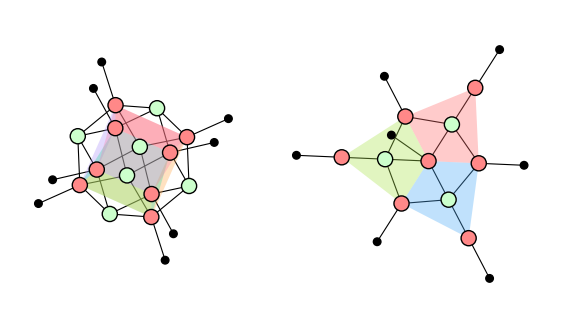

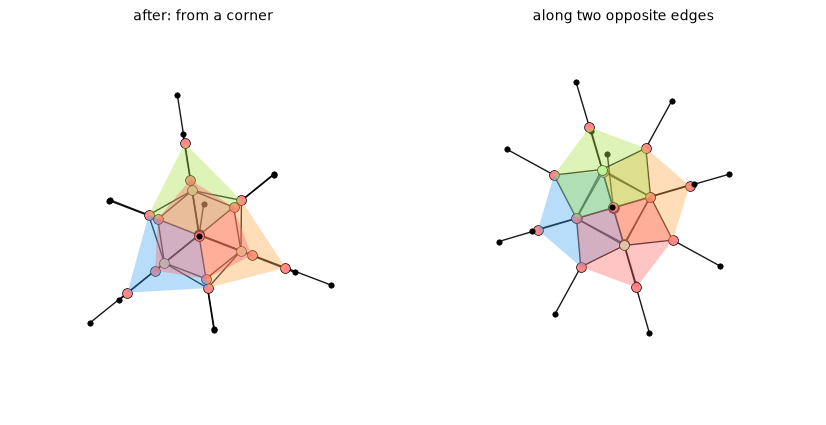

In [5]:
before = [[int(q in face) for q in range(15)] for face in TRIANGLE + CUBE_FACES]
display(draw_relaxed(check_diagram(before), shade='Z', boundaries='outward', figsize=(7, 4)))
draw_relaxed_3d(check_diagram(rows), shade='Z', boundaries='outward', box=False,
                views=[(2.7, -88.5), (56.4, -101.7)], titles=['after: from a corner', 'along two opposite edges'],
                spider_size=50)

## 3. Questions 2 and 3: what the switch does to the logical qubit

The level-up table: the switch, stages 2 and 3, leaves the logical state unchanged in every run. Its checks as a `code switching` block: it changes the code, keeps the code distance, and does nothing to the logical state.

In [6]:
print(p.summary(level))

block                   role               code before            code after             logical action  every run?  checks
0 Steane code           encoder            [[1,1,1]]              [[7,1,3]]              I               yes         ok
1 cube state, checked   state preparation  [[7,1,3]]              [[7,1,3]] + [[8,0,?]]  I               yes         ok
2 switch to [[15,1,3]]  code switching     [[7,1,3]] + [[8,0,?]]  [[15,1,3]]             I               yes         ok

Block 0 'Steane code' (encoder) -- stages 0
  code before: [[1,1,1]] on qubits 2
  code after:  [[7,1,3]] on qubits 0,1,2,3,4,5,6
  logical action: deterministic: every run implements I
  ok      encodes 1 logical qubit(s) into [[7,1,3]]
  ok      leaves the logical state unchanged

Block 1 'cube state, checked' (state preparation) -- stages 1
  code before: [[7,1,3]] on qubits 0,1,2,3,4,5,6
  code after:  [[7,1,3]] on qubits 0,1,2,3,4,5,6; [[8,0,?]] on qubits 7,8,9,10,11,12,13,14
  logical action: determinist

The block's measurements are listed as 2 *frame* and 1 *gauge*. The reduced diagram still carries $X$ on qubits 3–10 when $c[0] \oplus c[1] = 1$. That operator is one of the $X$-checks of [[15,1,3]], so it does nothing to the encoded state, which is why the logical action is $I$ in every run; the reduced diagram is simply not simplified modulo the checks of the code it ends in.

## 4. Fault tolerance: circuit distance

Question 1 gives the distance of the codes: 3 before and after. The *circuit* distance is the smallest number of faults, anywhere in the gates, that changes the logical state while no detector notices (`circuit_distance`, with Stim and `codedistance`: `pip install zxqec[distance]`). It is measured here from the Steane code, through the cube state and the switch, to the [[15,1,3]] code.

As written, it is 2: the tool finds a pair of faults that does it.

In [7]:
d = circuit_distance(plain, 1, 3)
print(d)
print("a fault set:", *d.explain(), sep="\n  ")

full circuit distance of stages 1-3: 2 (X -> X: 2, Z -> Z: 3)
a fault set:
  stage 1: Z11 Z14 after CX 11 14
  stage 2: Z6 Z15 after CX 6 15


One $Z$ fault while the cube state is prepared, and one on a helper while a gauge operator is measured (it spreads back to the data qubits that are still to be read). Together they change the logical state, and nothing notices. The cure is to check the cube state before it is used: measure four of its faces, $X$ on four qubits each, and keep it only if every outcome is 0. Those outcomes become detectors, and the circuit distance is 3, the distance of the codes, for every kind of fault:

In [8]:
for kind in ('full', 'Z', 'X'):
    print(kind, circuit_distance(p, 1, 3, kind=kind).distance)

full 3


Z 3


X 5


## Summary

* The tool reads both codes off the gates: the Steane code next to the cube state before the switch, the [[15,1,3]] Reed–Muller code after it, and in between the same code with outcome-dependent signs.
* The switch is the logical identity in every run: the three corrections, $X$ on a face of the Steane triangle each, fix every one of the eight combinations of outcomes.
* As written, the switch has circuit distance 2; with the cube state checked first, 3.

What is not covered: the corrections and the check of the cube state are given here, not found by the tool (finding corrections from the normal form is planned); and circuit distance counts the faults that go unnoticed, it does not decode.